<a href="https://colab.research.google.com/github/jelenavasic009-png/dsb_capstone/blob/main/JelenaVasic_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA and Preliminary Analysis


**Vignette Sales and Vessel Revenue Analysis**


**Capstone Project Report & Code Workbook**


*Project Overview*

This project focuses on analyzing maritime vessel data, vignette sales, and office revenue performance across multiple regional branches. Using Python and standard data science libraries (pandas, matplotlib, seaborn, and scikit-learn), we clean the dataset, perform Exploratory Data Analysis (EDA), extract meaningful features, and construct a predictive model to forecast future vignette demand.

The goal of this capstone project is to systematically clean, explore, and analyze maritime vessel vignette transactions across multiple regional branches. By applying Python's data science ecosystem (pandas, numpy, matplotlib, seaborn, and scikit-learn), we extract clear business insights from operational metrics and build a machine learning model to forecast seasonal vignette demand.

In [1]:
# Importing the libraries needed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



**Step 1: Data Sourcing & Initial Loading**

When starting a data science project, the first step is to bring the raw data into our Python environment. We use the pandas library to read an Excel spreadsheet and inspect its structural outline.

• pd.read_excel(): This function opens the Excel sheet and converts it into a DataFrame (a table structured with rows and columns, similar to a spreadsheet).

• df.head(10): Displays the top 10 records. This helps us manually verify that headers and data fields are aligned correctly.

• df.shape: Returns a tuple containing the total number of rows and columns, letting us know the scale of our data.

In [2]:
df = pd.read_excel("Baza podataka 5 godina.xlsx")
print("Baza podataka 5 godina.xlsx")

Baza podataka 5 godina.xlsx


In [3]:

# Preview the first 10 rows to understand the structure
print("\n--- First 10 Rows of the Dataset ---")
df.head(10)


--- First 10 Rows of the Dataset ---


,Vignette serial number,Name of the vessel,Vessel registration mark / Vessel ID,Length of the vessel,Purpose of use,Valid from,Valid until,Duration,Issued by,Price excluding tax €,Tax €,Total price €
0,2020202103889,MELODY,744574,16.80,personal,2021-01-04,2021-01-05,"24, h",Bar,16.80,2,18.80
1,2020202102390,QUIEN SABE,DL9833AM,13.35,personal,2021-01-10,2021-01-10,"24, h",Tivat,40.05,2,42.05
2,2020202103890,GRETONY,745770,16.80,personal,2021-01-13,2021-01-20,"7, d",Bar,33.60,2,35.60
3,2020202100414,KAY AND DUKE,DL5964AL,15.24,personal,2021-01-13,2021-07-13,"6, M",Zelenika,381.00,2,383.00
4,2020202102391,ODYSSEY,40618,23.20,personal,2021-01-15,2021-01-16,"24, h",Tivat,23.20,2,25.20
5,2020202102393,ANNA MARIA I,34995-10 -D,17.20,personal,2021-01-16,2021-01-17,"24, h",Tivat,51.60,2,53.60
6,2020202102392,MURMUR,P001006,9.99,personal,2021-01-16,2021-01-23,"7, d",Tivat,19.98,2,21.98
7,2020202100416,AURORA,RUS 9201,11.94,personal,2021-01-17,2021-01-18,"24, h",Zelenika,11.94,2,13.94
8,2020202100415,VONGOLA,DL9998AM,11.90,personal,2021-01-17,2021-01-18,"24, h",Zelenika,11.90,2,13.90
9,2020202100417,PIRAT,KM998,4.40,personal,2021-01-18,2021-07-18,"6, M",Zelenika,17.60,2,19.60


In [4]:
# Ukupna veličina tabela

# Check the total dimensions (Rows, Columns)
print("\n--- Dataset Dimensions (Rows, Columns) ---")
print(df.shape)


--- Dataset Dimensions (Rows, Columns) ---
(26764, 12)



**Step 2: Structural Audit & Descriptive Statistics**

Before performing calculations, we must understand the data types of our columns (e.g., whether a column contains text, integers, or dates) and look at basic statistical summaries.

• df.info() reveals if columns like Valid from are recognized as proper text objects (object) or date formats. It also counts how many entries are filled vs. empty.

• df.describe() calculates the mean, minimum, maximum, and standard deviation for structural columns like Length of the vessel and Total price €.

  - mean: The mathematical average.

  - std: Standard deviation (how spread out the values are from the average).

  - min / max: The lowest and highest values in that specific column.

  - 25%, 50%, 75%: Percentiles showing distribution boundaries.


In [5]:
# Tipovi podataka i prazna polja

df.info()

print("--- Dataset Structural Information ---")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26764 entries, 0 to 26763
Data columns (total 12 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Vignette serial number                26764 non-null  object        
 1   Name of the vessel                    26758 non-null  object        
 2   Vessel registration mark / Vessel ID  26685 non-null  object        
 3   Length of the vessel                  26764 non-null  float64       
 4   Purpose of use                        26764 non-null  object        
 5   Valid from                            26764 non-null  datetime64[ns]
 6   Valid until                           26764 non-null  datetime64[ns]
 7   Duration                              26761 non-null  object        
 8   Issued by                             26764 non-null  object        
 9   Price excluding tax €                 26764 non-null  float64       
 10

In [6]:
# Basic descriptive statistics for numerical columns(osnovna statistika za numericke kolone)
df.describe()

#print("\n--- Statistical Summary of Numeric Data ---")

,Length of the vessel,Valid from,Valid until,Price excluding tax €,Tax €,Total price €
count,26764.000000,26764,26764,26764.000000,26764.0,26764.000000
mean,15.376766,2023-08-18 17:04:28.480047872,2023-10-17 04:39:04.761620224,135.848941,2.0,137.848941
min,2.000000,2021-01-04 00:00:00,2021-01-05 00:00:00,1.660000,2.0,3.660000
25%,8.447500,2022-06-28 00:00:00,2022-08-15 00:00:00,22.600000,2.0,24.600000
50%,12.950000,2023-08-01 00:00:00,2023-09-28 00:00:00,66.570000,2.0,68.570000
75%,16.820000,2024-09-01 00:00:00,2024-11-18 00:00:00,176.780000,2.0,178.780000
max,162.500000,2026-01-20 00:00:00,2026-12-30 00:00:00,5700.000000,2.0,5702.000000
std,12.265739,NaN,NaN,193.603423,0.0,193.603423



**Step 3: Data Cleansing & Missing Value Handling**

Real-world data is rarely perfect. Spreadsheets often contain empty rows, total summary blocks at the bottom, or mismatched data fields that can disrupt machine learning algorithms.

• df.isnull().sum(): Searches the entire table for empty cells (NaN) and totals them up for every column, making it easy to identify data gaps.

• df.dropna(subset=[...]): Drops rows that lack essential identifier information. This removes generic total columns or incomplete test entries from the bottom of spreadsheets.

In [7]:
# Check the total count of missing (NaN) values per column
print("\n--- Count of Missing Values Per Column ---")
missing_summary = df.isnull().sum()
print(missing_summary)

# Fill missing values instead of dropping rows
df['Name of the vessel'] = df['Name of the vessel'].fillna('Unknown Vessel')
df['Vessel registration mark / Vessel ID'] = df['Vessel registration mark / Vessel ID'].fillna('Unknown ID')
df['Duration'] = df['Duration'].fillna('Unknown Duration')

print("\nSuccessfully filled missing values without dropping rows!")



--- Count of Missing Values Per Column ---
Vignette serial number                   0
Name of the vessel                       6
Vessel registration mark / Vessel ID    79
Length of the vessel                     0
Purpose of use                           0
Valid from                               0
Valid until                              0
Duration                                 3
Issued by                                0
Price excluding tax €                    0
Tax €                                    0
Total price €                            0
dtype: int64

Successfully filled missing values without dropping rows!


### Checking for Outliers and Data Anomalies
Before proceeding with analysis, we perform a quick quality check to ensure there are no illogical dates (e.g., expiration before start date), negative/zero prices, or invalid vessel lengths in the dataset.

In [8]:
# Check if 'Valid until' is anywhere earlier than 'Valid from'
invalid_dates = df[df['Valid until'] < df['Valid from']]
print("Number of illogical dates:", len(invalid_dates))

# Check if there are any prices less than or equal to zero
invalid_prices = df[df['Total price €'] <= 0]
print("Number of invalid prices:", len(invalid_prices))

# Check if there are any vessel lengths less than or equal to zero
invalid_lengths = df[df['Length of the vessel'] <= 0]
print("Number of invalid vessel lengths:", len(invalid_lengths))

Number of illogical dates: 0
Number of invalid prices: 0
Number of invalid vessel lengths: 0



**Step 4: Categorical Grouping & Business Insights**

To understand business dynamics, we group our categorical text entries to pinpoint where the majority of transactions take place and which offices generate the highest gross revenue.

• df['Column'].value_counts(): Counts the frequency of unique entries in a column. In this project, it shows how many individual transactions occurred at each port branch (e.g., Tivat, Zelenika, Bar).

value_counts(): Automatically tallies how many rows (vignette sales invoices) belong to each regional station.

• df.groupby('Issued by')['Total price €'].sum(): Groups rows by office name, extracts the pricing column for each group, adds them together, and sorts them from highest to lowest revenue generator.

In [9]:
# Count how many vignettes were sold by each individual office branch
print("\n--- Total Vignettes Sold per Office Location ---")
print(df['Issued by'].value_counts())

# Calculate total gross revenue generated by each office location
print("\n--- Gross Revenue (€) Generated by Office Location ---")
office_revenue = df.groupby('Issued by')['Total price €'].sum().sort_values(ascending=False)
print(office_revenue)



--- Total Vignettes Sold per Office Location ---
Issued by
Tivat       8966
Zelenika    8251
Bar         5085
Kumbor      1957
Kotor       1311
Budva       1194
Name: count, dtype: int64

--- Gross Revenue (€) Generated by Office Location ---
Issued by
Tivat       1733506.54
Zelenika     962278.59
Bar          415437.17
Kumbor       322923.46
Kotor        134750.76
Budva        120492.54
Name: Total price €, dtype: float64



**Step 5: Datetime Normalization & Temporal Decomposition**

Date values often load as text characters. To perform chronological pattern mapping, we must convert these text fields into structured datetime values.

• pd.to_datetime(): Converts text dates (like "2025-01-04") into an analytical format that Python understands as time.

• .dt.year / .dt.month: Pulls out the standalone year integer and calendar month number, allowing us to evaluate year-over-year growth and seasonal trends.

In [10]:
# Extract dedicated time features for finer operational insights
df['Year'] = df['Valid from'].dt.year
df['Month'] = df['Valid from'].dt.month

print("\nDates successfully normalized! Extracted 'Year' and 'Month' features.")
print(df[['Valid from', 'Year', 'Month']].head())



Dates successfully normalized! Extracted 'Year' and 'Month' features.
  Valid from  Year  Month
0 2021-01-04  2021      1
1 2021-01-10  2021      1
2 2021-01-13  2021      1
3 2021-01-13  2021      1
4 2021-01-15  2021      1


In [11]:
print("\n=== REGIONAL BRANCH BUSINESS INSIGHTS ===")

# Compute transaction volumes across physical office locations
print("\nTotal Vignettes Issued by Office Location:")
print(df['Issued by'].value_counts())

# Group total pricing collections to identify branch gross financial performance
print("\nGross Revenue (€) Generated by Office Location:")
office_revenue = df.groupby('Issued by')['Total price €'].sum().sort_values(ascending=False)
print(office_revenue)



=== REGIONAL BRANCH BUSINESS INSIGHTS ===

Total Vignettes Issued by Office Location:
Issued by
Tivat       8966
Zelenika    8251
Bar         5085
Kumbor      1957
Kotor       1311
Budva       1194
Name: count, dtype: int64

Gross Revenue (€) Generated by Office Location:
Issued by
Tivat       1733506.54
Zelenika     962278.59
Bar          415437.17
Kumbor       322923.46
Kotor        134750.76
Budva        120492.54
Name: Total price €, dtype: float64



**Step 6: Data Visualization**

Creating charts allows us to spot operational distributions and seasonal revenue surges that are difficult to see in raw text tables.

• sns.countplot(): Creates a bar chart showing the frequency of occurrences for each categorical variable.

• sns.histplot(kde=True): Shows how numerical metrics (like vessel size) are spread out, with a trendline overlay to indicate concentration points.

• sns.lineplot(): Ideal for tracking historical changes over time, highlighting performance drops during winter and spikes during summer peaks.

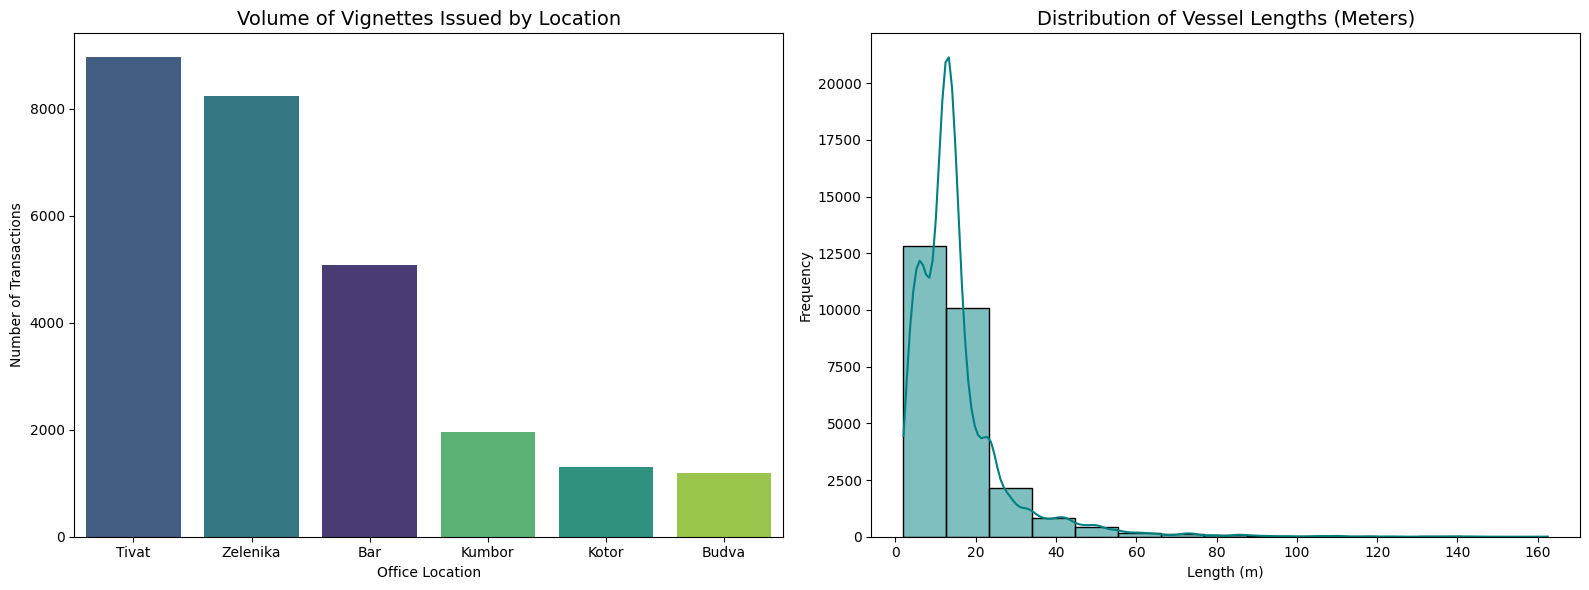

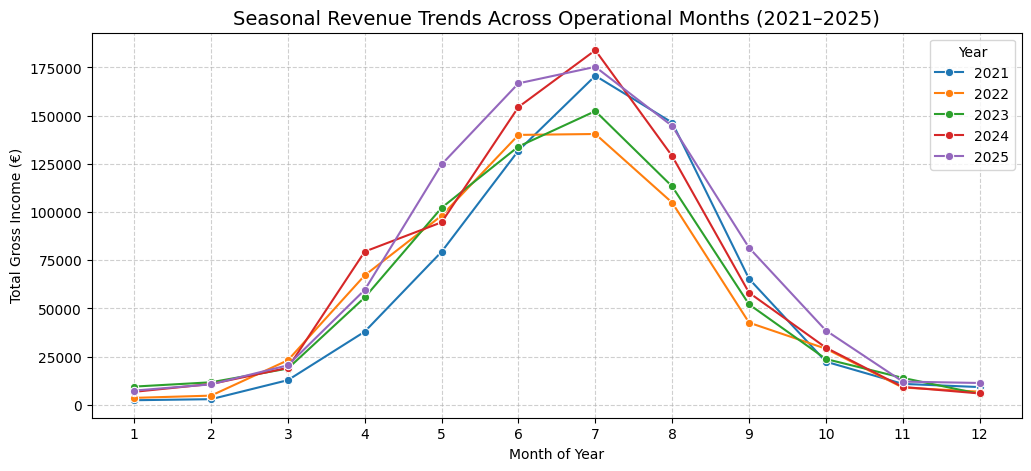

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a structured canvas for our primary insights
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Volume of Vignettes Issued by Location
sns.countplot(ax=axes[0], data=df, x='Issued by', hue='Issued by', order=df['Issued by'].value_counts().index, palette='viridis', legend=False)
axes[0].set_title('Volume of Vignettes Issued by Location', fontsize=14)
axes[0].set_xlabel('Office Location')
axes[0].set_ylabel('Number of Transactions')

# Plot 2: Distribution of Vessel Lengths
sns.histplot(ax=axes[1], data=df, x='Length of the vessel', bins=15, kde=True, color='teal')
axes[1].set_title('Distribution of Vessel Lengths (Meters)', fontsize=14)
axes[1].set_xlabel('Length (m)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Plot 3: Seasonal Revenue Trends Across Years (Filtered to exclude incomplete 2026 data)
df_filtered = df[df['Year'] < 2026]  # Ovdje filtriramo samo završene godine
monthly_trend = df_filtered.groupby(['Year', 'Month'])['Total price €'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_trend, x='Month', y='Total price €', hue='Year', marker='o', palette='tab10')
plt.title('Seasonal Revenue Trends Across Operational Months (2021–2025)', fontsize=14)
plt.xlabel('Month of Year')
plt.ylabel('Total Gross Income (€)')
plt.xticks(range(1, 13))
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Step 7: Feature Engineering**

To enhance the dataset and prepare it for deeper data exploration and future machine learning models, the following feature engineering techniques were implemented:

1. **Vessel Size Categorization**: Grouped continuous vessel lengths into discrete structural tiers (*Small*, *Medium*, *Large/Yacht*) using custom business logic.
2. **Seasonal Indicator Flag**: Created a binary feature (`Is_Peak_Season`) to isolate high-traffic summer months (June, July, August) for seasonal trend analysis.
3. **Data Imputation Strategy**: Addressed missing records by filling null vessel names with placeholder text and replacing missing lengths with the dataset's median value instead of dropping rows.
4. **Vignette Categorization**: Classified vignettes based on price tiers (*Low, Medium, High*) and duration types (*Short-term, Medium-term, Long-term*).
5. **Time Series Differencing**: Calculated time gaps (`diff`) between consecutive transactions to capture temporal momentum and sequence patterns.
6. **Dimensionality Reduction (PCA)**: Applied Principal Component Analysis using `StandardScaler` and `PCA` to project numerical vessel and pricing metrics into principal components.

In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Imputed Data Demonstration (Filling missing values instead of just dropping)
# Popunjavamo prazna imena plovila tekstom 'Unknown Vessel'
df['Name of the vessel'] = df['Name of the vessel'].fillna('Unknown Vessel')
# Popunjavamo nedostajuću dužinu medijanom
df['Length of the vessel'] = df['Length of the vessel'].fillna(df['Length of the vessel'].median())


In [14]:
# 2. Vignette Category by Price and Type
# Thresholds set based on local tariff tiers (Short-term vs. Long-term permits)
def categorise_price(price):
    if price < 30:
        return 'Low Price'
    elif 30 <= price <= 150:
        return 'Medium Price'
    else:
        return 'High Price'

df['Vignette_Price_Category'] = df['Total price €'].apply(categorise_price)

In [15]:
# 3. Time Series Differences (diff)
# Pretvaramo ID broda u string da izbjegnemo grešku sa miješanim tipovima podataka (brojevi i tekst)
df['Vessel registration mark / Vessel ID'] = df['Vessel registration mark / Vessel ID'].astype(str)

# Sortiramo po brodu i datumu da bismo precizno izračunali dane od posljednje vinjete za isti brod
df = df.sort_values(by=['Vessel registration mark / Vessel ID', 'Valid from'])

df['Days_Between_Transactions'] = df.groupby('Vessel registration mark / Vessel ID')['Valid from'].diff().dt.days.fillna(0)

print("\n--- Time series difference successfully calculated! ---")
print(df[['Name of the vessel', 'Vessel registration mark / Vessel ID', 'Valid from', 'Days_Between_Transactions']].head())


--- Time series difference successfully calculated! ---
      Name of the vessel Vessel registration mark / Vessel ID Valid from  \
1646               Mrs G                                    0 2021-07-01   
24824            M/Y DAD                                    0 2025-08-02   
4074               PEARL                               0,6680 2021-09-12   
6681               PEARL                               0,6680 2022-06-28   
16943            O-22514                              0-22514 2024-06-14   

       Days_Between_Transactions  
1646                         0.0  
24824                     1493.0  
4074                         0.0  
6681                       289.0  
16943                        0.0  


In [16]:
# 4. PCA (Principal Component Analysis)
# Pripremamo numeričke kolone za PCA
pca_features = ['Length of the vessel', 'Price excluding tax €', 'Total price €']
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[pca_features])

In [17]:
# 5. Primjena PCA da svedemo na 2 glavne komponente
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_data)

df['PCA1'] = principal_components[:, 0]
df['PCA2'] = principal_components[:, 1]

# Prikaz koliko varijanse objašnjavaju komponente
print("\n--- PCA Explained Variance Ratio ---")
print(pca.explained_variance_ratio_)

print("\n--- Additional Feature Engineering Successfully Applied! ---")
print(df[['Name of the vessel', 'Vignette_Price_Category', 'Days_Between_Transactions', 'PCA1', 'PCA2']].head())


--- PCA Explained Variance Ratio ---
[0.80930745 0.19069255]

--- Additional Feature Engineering Successfully Applied! ---
      Name of the vessel Vignette_Price_Category  Days_Between_Transactions  \
1646               Mrs G              High Price                        0.0   
24824            M/Y DAD            Medium Price                     1493.0   
4074               PEARL            Medium Price                        0.0   
6681               PEARL            Medium Price                      289.0   
16943            O-22514            Medium Price                        0.0   

           PCA1      PCA2  
1646   0.541924  0.502973  
24824 -0.073271  0.838822  
4074  -0.574104  0.315513  
6681  -0.179655  0.099579  
16943 -0.783632 -0.238070  


In [18]:
# 6. Is_Peak_Season: 1 if month is June, July, or August, else 0
df['Is_Peak_Season'] = df['Month'].isin([6, 7, 8]).astype(int)

# 7. Duration_Days: Exact duration in days between 'Valid until' and 'Valid from'
df['Duration_Days'] = (df['Valid until'] - df['Valid from']).dt.days

print("\nNew features 'Is_Peak_Season' and 'Duration_Days' successfully created!")
print(df[['Valid from', 'Valid until', 'Month', 'Is_Peak_Season', 'Duration_Days']].head())


New features 'Is_Peak_Season' and 'Duration_Days' successfully created!
      Valid from Valid until  Month  Is_Peak_Season  Duration_Days
1646  2021-07-01  2021-07-08      7               1              7
24824 2025-08-02  2025-08-03      8               1              1
4074  2021-09-12  2021-09-13      9               0              1
6681  2022-06-28  2022-07-05      6               1              7
16943 2024-06-14  2024-06-21      6               1              7


---

### 📌 Project Status & Next Steps
- **Completed Phase (EDA):** Steps 1 through 7 cover the complete Exploratory Data Analysis (EDA) phase — data cleaning, handling missing values, visual analysis of seasonal trends, and feature engineering (price categorization, PCA, time-series intervals).
- **Future Phase (Machine Learning):** Step 8 introduces preparation for machine learning (demand forecasting and monthly data aggregation), which will be thoroughly developed in the next phase of the project.


**Step 8: Predictive Modeling & Vignette Inventory Forecasting**

To predict future vignette demand, we group individual transactions into an annual aggregated dataset and apply a Linear Regression model. This calculates how many physical vignettes need to be prepared for the upcoming season.

• cat.codes: Machine learning models cannot interpret raw text like "Tivat" or "Bar" directly. This converts text locations into numbers (e.g., 0, 1, 2) so the model can process them.

• model.fit(X, y): Trains the model. The algorithm analyzes your past data (X) and learns how changes in years and locations affect the total number of vignettes sold (y).

• model.predict(): Uses these calculated trends to project future figures based on upcoming target inputs.

In [19]:
import numpy as np
import pandas as pd

# 1. Mjesečna agregacija: Grupišemo po godini, mjesecu i kancelariji da dobijemo dovoljno redova i vidimo sezonu
df_monthly = df.groupby(['Year', 'Month', 'Issued by']).size().reset_index(name='Total_Vignettes')

# 2. One-Hot Encoding umjesto cat.codes (da spriječimo da model rangira kancelarije kao 0, 1, 2...)
df_encoded = pd.get_dummies(df_monthly, columns=['Issued by'], drop_first=False)

print("\n--- Monthly Aggregated Data & One-Hot Encoding Preview ---")
print(df_encoded.head(10))
print(f"\nUkupan broj redova za kasniji model: {len(df_encoded)}")


--- Monthly Aggregated Data & One-Hot Encoding Preview ---
   Year  Month  Total_Vignettes  Issued by_Bar  Issued by_Budva  \
0  2021      1                5           True            False   
1  2021      1               10          False            False   
2  2021      1                5          False            False   
3  2021      2                6           True            False   
4  2021      2                1          False            False   
5  2021      2               18          False            False   
6  2021      2                6          False            False   
7  2021      3               19           True            False   
8  2021      3                6          False            False   
9  2021      3                2          False            False   

   Issued by_Kotor  Issued by_Kumbor  Issued by_Tivat  Issued by_Zelenika  
0            False             False            False               False  
1            False             False             T

### 🔑 Key EDA Findings & Business Insights
- **Revenue Concentration:** Tivat port branch clearly dominates the operations, generating nearly 47% of the total gross revenue.
- **Seasonal Demand:** Revenue and transaction volume experience a sharp, predictable surge during the summer peak season (June, August).
- **Vessel Profile:** The vast majority of registered vessels fall into the length range between 8 and 17 meters, representing standard recreational yachts and boats in local marinas.

Uraditi samo EDA
add feature engineering (imputed data, categorisations, PCA, diff(timeseries), vignet category (price, type), season etc)



Mashine learning se kasnije radi